# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [9]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
# cargar archivos
plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [11]:
# mostrar las primeras 5 filas de plans
print("Primeras filas de plans:")
display(plans.head())

print("Primeras filas de users:")
display(users.head())

print("Primeras filas de usage:")
display(usage.head())


Primeras filas de plans:


,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


Primeras filas de users:


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


Primeras filas de usage:


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [12]:
# mostrar las primeras 5 filas de users
print("\nPrimeras filas de users:")
display(users.head())


Primeras filas de users:


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [13]:
# mostrar las primeras 5 filas de usage
print("\nPrimeras filas de usage:")
display(usage.head())


Primeras filas de usage:


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [14]:
# revisar el número de filas y columnas de cada dataset



In [15]:
print("Dimensiones de plans:")
print(plans.shape)

print("\nInformación de plans:")
plans.info()

# ----- Estructura de users -----
print("\nDimensiones de users:")
print(users.shape)

print("\nInformación de users:")
users.info()

# ----- Estructura de usage -----
print("\nDimensiones de usage:")
print(usage.shape)

print("\nInformación de usage:")
usage.info()

Dimensiones de plans:
(2, 8)

Información de plans:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes

Dimensiones de users:
(4000, 8)

Información de users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  40

---




In [16]:


# Dataset plans
print("=== VALORES NULOS: PLANS ===")
print(plans.isna().sum())
print("\nProporción de nulos en plans:")
print(plans.isna().mean())

# Dataset users
print("\n=== VALORES NULOS: USERS ===")
print(users.isna().sum())
print("\nProporción de nulos en users:")
print(users.isna().mean())

# Dataset usage
print("\n=== VALORES NULOS: USAGE ===")
print(usage.isna().sum())
print("\nProporción de nulos en usage:")
print(usage.isna().mean())




# El dataset plans tiene solo 2 filas y no presenta valores ausentes,
# por lo que no necesita exploración adicional.




=== VALORES NULOS: PLANS ===
plan_name            0
messages_included    0
gb_per_month         0
minutes_included     0
usd_monthly_pay      0
usd_per_gb           0
usd_per_message      0
usd_per_minute       0
dtype: int64

Proporción de nulos en plans:
plan_name            0.0
messages_included    0.0
gb_per_month         0.0
minutes_included     0.0
usd_monthly_pay      0.0
usd_per_gb           0.0
usd_per_message      0.0
usd_per_minute       0.0
dtype: float64

=== VALORES NULOS: USERS ===
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

=== VALORES NULOS: USAGE ===
id              0
user_id         0
type            0
date           50
duration 

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- **Diagnóstico de valores nulos**

Se revisaron los valores faltantes de los tres datasets mediante `isna().sum()` y `isna().mean()`. El primer método permite conocer la cantidad de nulos por columna y el segundo permite calcular su proporción.

En `plans`, se debe verificar si existen valores faltantes antes de decidir si requiere tratamiento. En `users` y `usage`, se deben identificar las columnas afectadas, cuantificar los faltantes y analizar su significado.

No se eliminarán ni imputarán valores automáticamente. Las decisiones se tomarán teniendo en cuenta la proporción de datos faltantes y la importancia de cada variable para el análisis.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [17]:
# explorar columnas numéricas de users

print("Resumen estadístico de users:")
print(users.describe())

print("\nValores únicos de age:")
print(sorted(users["age"].dropna().unique()))


Resumen estadístico de users:
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

Valores únicos de age:
[-999, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79]


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [18]:
# explorar columnas numéricas de usage

print("Resumen estadístico de usage:")
print(usage.describe())


Resumen estadístico de usage:
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [19]:
# explorar columnas categóricas de users

columnas_user = ["city", "plan"]

for col in columnas_user:
    print(f"\nValores únicos de {col}:")
    print(users[col].value_counts(dropna=False))




Valores únicos de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` ...
- La columna `plan` ...

In [20]:
# explorar columna categórica de usage
usage['type']
print("Tipos de registros en usage:")
print(usage["type"].value_counts(dropna=False))


Tipos de registros en usage:
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
- **Diagnóstico de valores inválidos o sentinels**

Se exploraron las variables numéricas mediante estadísticas descriptivas y las variables categóricas mediante sus valores únicos y frecuencias.

Se debe comprobar si `age` contiene el valor sentinel `-999` y si `city` contiene `"?"`. Si se encuentran estos valores, se tratarán según las instrucciones del proyecto. También se revisarán los identificadores y las variables de uso para detectar valores que no sean coherentes con su significado.

Las decisiones definitivas se tomarán después de verificar los resultados obtenidos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:
# Convertir a fecha la columna `reg_date` de users
users["reg_date"] = pd.to_datetime(
    users["reg_date"],
    errors="coerce"
)

print(users["reg_date"].dtype)


datetime64[ns]


In [22]:
# Convertir a fecha la columna `date` de usage

usage["date"] = pd.to_datetime(
    usage["date"],
    errors="coerce"
)

print(usage["date"].dtype)


datetime64[ns]


In [23]:
# Revisar los años presentes en `reg_date` de users

print("Años de registro de users:")
print(users["reg_date"].dt.year.value_counts().sort_index())



Años de registro de users:
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [24]:
# Revisar los años presentes en `date` de usage

print("Años de usage:")
print(usage["date"].dt.year.value_counts().sort_index())



Años de usage:
2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.
**Diagnóstico de fechas**

Las columnas `reg_date` y `date` se convirtieron al tipo datetime para facilitar el análisis temporal. Posteriormente, se revisó la distribución por año y se identificaron posibles registros posteriores a 2024.

Las fechas que no puedan interpretarse correctamente deben investigarse. Las fechas posteriores a 2024 deben marcarse como inválidas para este análisis, de acuerdo con el periodo definido en el proyecto.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age

# Calcular la mediana sin considerar el sentinel
age_mediana = users.loc[
    users["age"] != -999, "age"
].median()

# Reemplazar el sentinel por la mediana
users["age"] = users["age"].replace(-999, age_mediana)

# Verificar los cambios
print(users["age"].describe())
print("Cantidad de sentinels restantes:", (users["age"] == -999).sum())


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64
Cantidad de sentinels restantes: 0


In [26]:
# Reemplazar ? por NA en city

users["city"] = users["city"].replace("?", pd.NA)

# Verificar los cambios
print(users["city"].value_counts(dropna=False))


# Verificar cambios


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [27]:
# Marcar fechas futuras como NA para reg_date


# Fechas de registro posteriores a 2024
users.loc[users["reg_date"].dt.year > 2024, "reg_date"] = pd.NaT

# Verificar
print(users["reg_date"].dt.year.value_counts().sort_index())

# Verificar cambios

# Fechas de uso posteriores a 2024
usage.loc[usage["date"].dt.year > 2024, "date"] = pd.NaT

# Verificar
print(usage["date"].dt.year.value_counts().sort_index())



2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64
2024.0    39950
Name: date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [32]:
# Verificación MAR en usage (Missing At Random) para duration

print("Proporción de nulos en duration según type:")

print(
    usage.groupby("type")["duration"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)



Proporción de nulos en duration según type:
type
call     0.00
text    99.93
Name: duration, dtype: float64


In [39]:
# Verificación MAR en usage (Missing At Random) para length
print("Proporción de nulos en length según type:")

print(
    usage.groupby("type")["length"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)


Proporción de nulos en length según type:
type
call    99.93
text     0.00
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [42]:
# Columnas auxiliares

# Crear el DataFrame agrupado por tipo
usage_agg = usage.groupby("type").agg(
    total_registros=("type", "count"),
    nulos_duration=("duration", lambda x: x.isna().sum()),
    nulos_length=("length", lambda x: x.isna().sum())
).reset_index()

# Observar el resultado
display(usage_agg.head(3))

# Ver las columnas
print(usage_agg.columns)

,type,total_registros,nulos_duration,nulos_length
0,call,17908,0.0,17896.0
1,text,22092,22076.0,0.0


Index(['type', 'total_registros', 'nulos_duration', 'nulos_length'], dtype='object')


In [46]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

,type,total_registros,nulos_duration,nulos_length
0,call,17908,0.0,17896.0
1,text,22092,22076.0,0.0


In [50]:
# Combinar la tabla agregada con el dataset de usuarios

print(usage.columns.tolist())
print(usage.head(3))




['id', 'user_id', 'type', 'date', 'duration', 'length', 'is_text', 'is_call']
   id  user_id  type                          date  duration  length  is_text  \
0   1    10332  call 2024-01-01 00:00:00.000000000      0.09     NaN        0   
1   2    11458  text 2024-01-01 00:06:30.969774244       NaN    39.0        1   
2   3    11777  text 2024-01-01 00:13:01.939548488       NaN    36.0        1   

   is_call  
0        1  
1        0  
2        0  


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [52]:
# Resumen estadístico de las columnas numéricas
# Resumen estadístico de las columnas numéricas
# Resumen de mensajes por usuario
mensajes_usuario = usage[usage["type"] == "text"].groupby("user_id").size()

# Resumen de llamadas por usuario
llamadas_usuario = usage[usage["type"] == "call"].groupby("user_id").agg(
    cant_llamadas=("duration", "count"),
    cant_minutos_llamada=("duration", "sum")
)

# Construir el perfil de usuarios
user_profile = users.copy()

user_profile["cant_mensajes"] = (
    user_profile["user_id"].map(mensajes_usuario).fillna(0)
)

user_profile = user_profile.merge(
    llamadas_usuario,
    on="user_id",
    how="left"
)

user_profile[["cant_llamadas", "cant_minutos_llamada"]] = (
    user_profile[["cant_llamadas", "cant_minutos_llamada"]].fillna(0)
)

display(user_profile.head())



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [ ]:
# Distribución porcentual del tipo de plan


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

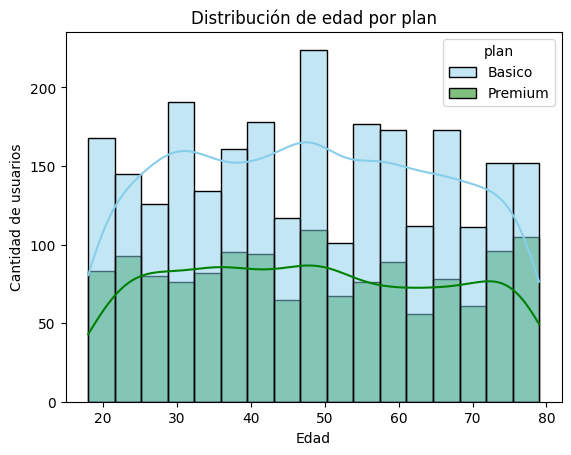

In [53]:
# Histograma para visualizar la edad (age)

# Histograma de edad
sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    palette=["skyblue", "green"],
    kde=True
)

plt.title("Distribución de edad por plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
la mayor cantidad de usuarios se encuentran en el plan basico en la edad de 50 años y de la misma manera esa misma edad representa la mayor concentracion de usuarios en el plan premium.

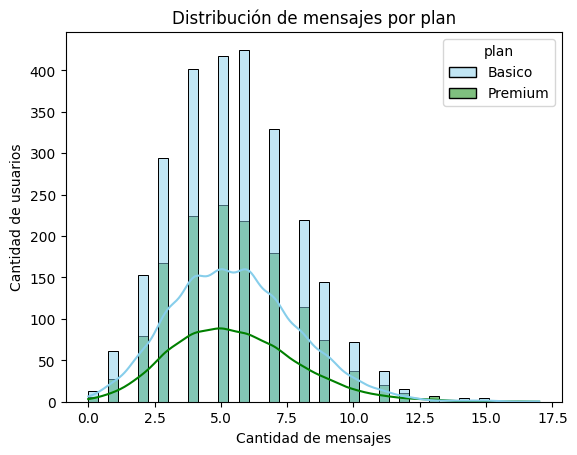

In [54]:
# Histograma para visualizar la cant_mensajes

# Histograma de mensajes
sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    palette=["skyblue", "green"],
    kde=True
)

plt.title("Distribución de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()



💡Insights: 
- Ambos planes tienen un comportamiento muy parecido

Las dos distribuciones tienen forma de campana y están centradas aproximadamente entre 5 y 6 mensajes.
Esto sugiere que el número de mensajes por usuario es relativamente similar entre ambos grupos.
Los usuarios Premium parecen enviar ligeramente más mensajes
La curva verde (Premium) parece estar un poco desplazada hacia la derecha.
Hay una mayor presencia relativa de usuarios Premium en rangos de 6 a 9 mensajes.
Esto podría indicar un engagement ligeramente superior en Premium.

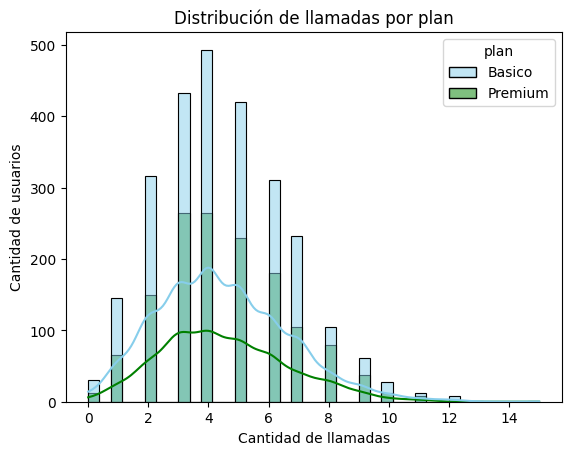

In [55]:
# Histograma para visualizar la cant_llamadas

# Histograma de llamadas
sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    palette=["skyblue", "green"],
    kde=True
)

plt.title("Distribución de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()



💡Insights: 
- El uso de llamadas también está concentrado en niveles medios
La mayor parte de los usuarios realiza entre 3 y 6 llamadas.
El pico de la distribución parece estar cerca de 4 llamadas para ambos planes.

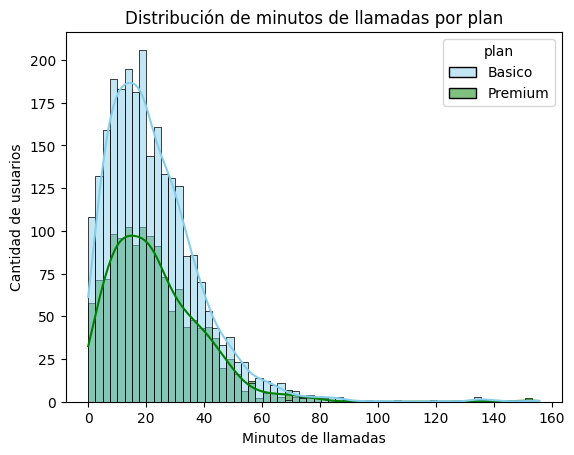

In [56]:
# Histograma para visualizar la cant_minutos_llamada

# Histograma de minutos de llamadas
sns.histplot(
    data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    palette=["skyblue", "green"],
    kde=True
)

plt.title("Distribución de minutos de llamadas por plan")
plt.xlabel("Minutos de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- se nota ademas de mayor concentracion de usuarios basicos que premium ambos se concentran en 20 minutos de llamada y bajan conformemente.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

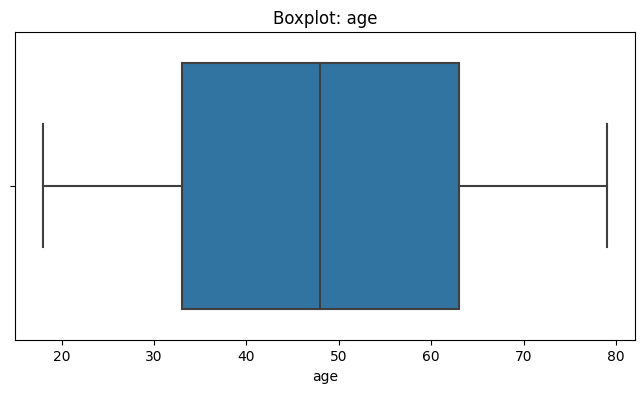

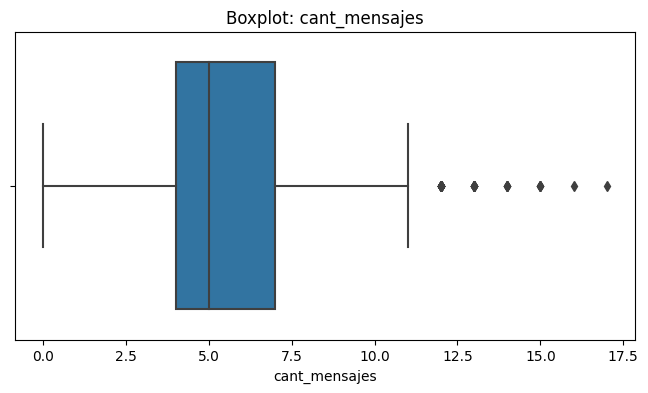

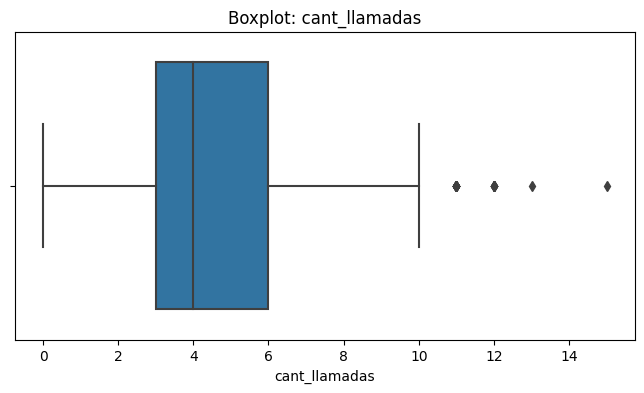

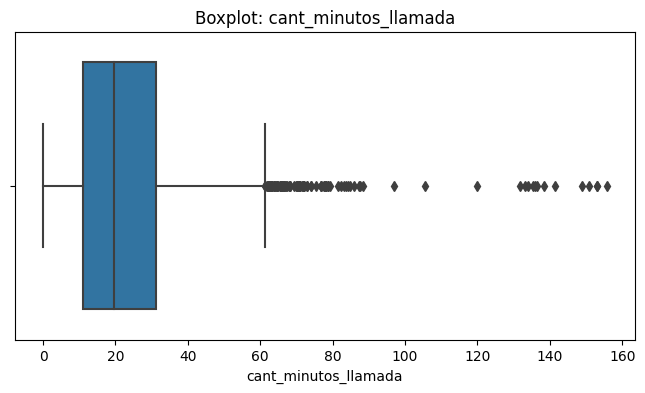

In [57]:
# Visualizando usando BoxPlot 

columnas_numericas = [
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()


💡Insights: 
- Age: ningun outliars
- cant_mensajes:La gran mayoría de usuarios tiene una actividad moderada, concentrada alrededor de 5 mensajes. Existe un pequeño grupo de usuarios muy activos que envían entre 12 y 17 mensajes, muy por encima del comportamiento habitual. tiene outliars.
- cant_llamadas: La mayoría de usuarios presenta un patrón de uso moderado, concentrado entre 2 y 6 llamadas. Sin embargo, existe un grupo reducido de usuarios que realiza más de 10 llamadas, comportándose de forma significativamente distinta al resto. tiene outliars
- cant_minutos_llamada: La mayoría de los usuarios acumula entre 10 y 30 minutos de llamadas, pero existe un segmento reducido que consume una cantidad de minutos muy superior al comportamiento habitual.

In [58]:
# Calcular límites con el método IQR

columnas_limites = [
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    cantidad_outliers = (
        (user_profile[col] < limite_inferior) |
        (user_profile[col] > limite_superior)
    ).sum()

    print(f"\nVariable: {col}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de outliers: {cantidad_outliers}")





Variable: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50
Cantidad de outliers: 46

Variable: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50
Cantidad de outliers: 30

Variable: cant_minutos_llamada
Límite inferior: -19.05
Límite superior: 61.32
Cantidad de outliers: 96


In [59]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.831225
std,2.359738,2.145139,16.592068
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.735000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


💡Insights: 
Se utilizaron diagramas de caja para identificar observaciones extremas en edad, mensajes, llamadas y minutos de llamadas. Para las variables de uso se calcularon los límites mediante el método IQR.
Los valores que superan los límites estadísticos se investigarán antes de eliminarlos. Un consumo elevado puede representar un comportamiento real de un cliente y resultar útil para diseñar planes comerciales. Por ello, los outliers no se eliminarán únicamente por ser extremos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [60]:
# Crear columna grupo_uso

condiciones_uso = [
    (user_profile["cant_llamadas"] < 5) &
    (user_profile["cant_mensajes"] < 5),

    (user_profile["cant_llamadas"] < 10) &
    (user_profile["cant_mensajes"] < 10)
]

categorias_uso = [
    "Bajo uso",
    "Uso medio"
]

user_profile["grupo_uso"] = pd.Series(
    "Alto uso",
    index=user_profile.index,
    dtype="object"
)

user_profile["grupo_uso"] = pd.Series(
    __import__("numpy").select(
        condiciones_uso,
        categorias_uso,
        default="Alto uso"
    ),
    index=user_profile.index
)

user_profile[["user_id", "cant_llamadas",
              "cant_mensajes", "grupo_uso"]].head()


,user_id,cant_llamadas,cant_mensajes,grupo_uso
0,10000,3.0,7.0,Uso medio
1,10001,10.0,5.0,Alto uso
2,10002,2.0,5.0,Uso medio
3,10003,3.0,11.0,Alto uso
4,10004,3.0,4.0,Bajo uso


In [61]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [62]:
# Crear columna grupo_edad

import numpy as np

condiciones_edad = [
    user_profile["age"] < 30,
    user_profile["age"] < 60
]

categorias_edad = [
    "Joven",
    "Adulto"
]

user_profile["grupo_edad"] = np.select(
    condiciones_edad,
    categorias_edad,
    default="Adulto Mayor"
)

user_profile[["user_id", "age", "grupo_edad"]].head()


,user_id,age,grupo_edad
0,10000,38.0,Adulto
1,10001,53.0,Adulto
2,10002,57.0,Adulto
3,10003,69.0,Adulto Mayor
4,10004,63.0,Adulto Mayor


In [63]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

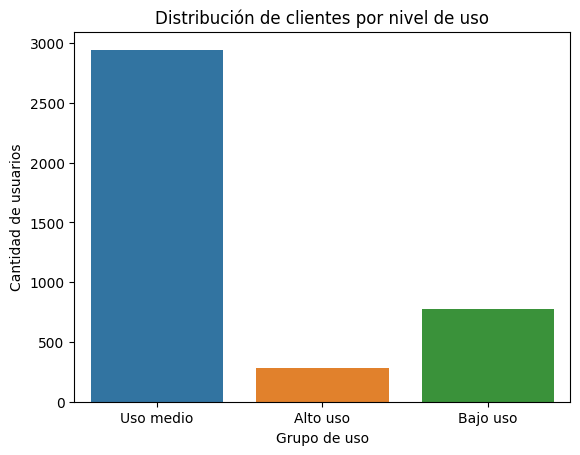

In [64]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x="grupo_uso")
plt.title("Distribución de clientes por nivel de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()


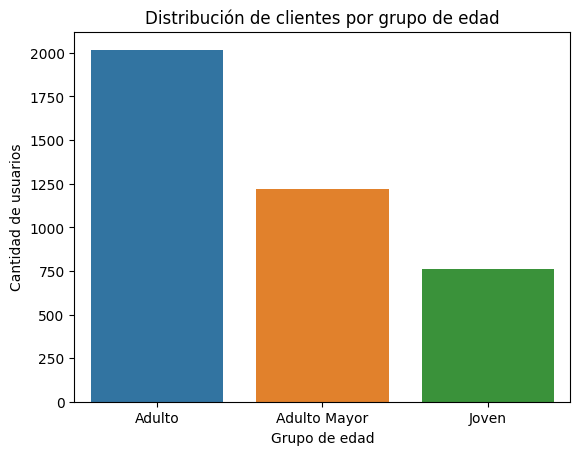

In [65]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x="grupo_edad")
plt.title("Distribución de clientes por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

  
 Valores nulos: se identificaron las columnas con datos faltantes y se calculó su proporción para determinar cuáles requieren una investigación adicional.
 
Sentinels: se revisaron posibles valores inválidos en edad y ciudad, aplicando las correcciones definidas en el proyecto.

Fechas: se estandarizaron las columnas temporales y se identificaron posibles fechas fuera del periodo de análisis.

Valores atípicos: se utilizaron diagramas de caja y el método IQR para detectar consumos extremos.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
  
Los usuarios se clasificaron en bajo uso, uso medio y alto uso a partir de sus llamadas y mensajes. Esta segmentación permite explorar diferencias de comportamiento y posibles oportunidades comerciales.

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
  
  Se recomienda comparar el consumo real con las condiciones y los precios de los planes Básico y Premium antes de proponer modificaciones
  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Los clientes con consumos elevados podrían beneficiarse de alternativas adaptadas a sus necesidades, mientras que los clientes de bajo uso podrían responder a ofertas más económicas o a estrategias de fidelización.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
creacion de nuevos planes con la finalidad de divercificar y apuntar a los puntos altos que expone cada grafico como ejemplo serian plan de voz plus o plan de mensajeria pro lo que motivaria a los clientes basicos y mantendria a los premium.
✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- El análisis de los datos evidencia que los clientes presentan patrones de consumo muy diferentes, mientras que la oferta actual de planes resulta relativamente limitada para satisfacer estas necesidades específicas.


🔍 **Segmentos por Edad**
- El estudio muestra que la edad influye en los patrones de consumo de los clientes. Los usuarios más jóvenes tienden a presentar comportamientos distintos a los de los grupos de mayor edad, lo que sugiere que una estrategia comercial uniforme puede resultar menos efectiva.

📊 **Segmentos por Nivel de Uso**
- A partir de los datos pueden identificarse tres grupos principales:

Usuarios de bajo consumo

Utilizan una proporción reducida de los recursos incluidos.
Podrían beneficiarse de planes básicos con tarifas más económicas.
Representan una oportunidad para reducir cancelaciones por percepción de sobreprecio.

Usuarios de consumo medio

Constituyen el grupo más equilibrado.
Suelen ajustarse adecuadamente a la oferta estándar.
Son candidatos ideales para estrategias de fidelización.

Usuarios de alto consumo

Alcanzan o superan frecuentemente los límites del plan.
Requieren opciones premium o paquetes adicionales.
Representan clientes de alto valor para la compañía.


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- Los resultados sugieren que la empresa podría mejorar significativamente su oferta mediante una estrategia de segmentación basada en la edad y el nivel de consumo de sus clientes. La creación de planes más específicos para usuarios de bajo, medio y alto uso permitiría aumentar la satisfacción del cliente, reducir la tasa de abandono y maximizar los ingresos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`